# Atividade 6: desocupação por sexo e afazeres domésticos

Este notebook junta as duas Tabelas 5, calcula a variação da participação das mulheres entre as pessoas desocupadas e cruza os 27 estados com a Tabela 1.1.1 do IBGE (2022), tratada conforme a Aula 2.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="Set2")

In [2]:
pasta = Path("H:/Python 3Etapa/analise_dados/Atividade6")
if not pasta.exists():
    pasta = Path.cwd()
    if not (pasta / "Tabela5-sem_emprego_2012.csv").exists():
        pasta = pasta / "analise_dados" / "Atividade6"

path_2012 = pasta / "Tabela5-sem_emprego_2012.csv"
path_2026 = pasta / "Tabela5-sem_emprego_2026.csv"
path_horas_csv = pasta / "Tabela1_1_1_horas.csv"
path_horas_xls = Path("H:/Tabela 1.1.1.xls")
if not path_horas_xls.exists():
    path_horas_xls = pasta / "Tabela 1.1.1.xls"

In [3]:
t2012 = pd.read_csv(path_2012, sep=";", decimal=",", encoding="utf-8-sig")
t2026 = pd.read_csv(path_2026, sep=";", decimal=",", encoding="utf-8-sig")

t2012 = t2012.rename(columns={
    "Desocupados - homens (2012 T1)": "homens_2012",
    "Desocupados - mulheres (2012 T1)": "mulheres_2012",
})
t2026 = t2026.rename(columns={
    "Desocupados - homens (2026 T1)": "homens_2026",
    "Desocupados - mulheres (2026 T1)": "mulheres_2026",
})
t2012

,Sigla,Código,Estado,homens_2012,mulheres_2012
0,AC,12,Acre,45.3,54.7
1,AL,27,Alagoas,44.7,55.3
2,AM,13,Amazonas,47.5,52.5
3,AP,16,Amapá,48.1,51.9
4,BA,29,Bahia,43.8,56.2
5,CE,23,Ceará,51.1,48.9
6,DF,53,Distrito Federal,41.0,59.0
7,ES,32,Espírito Santo,46.4,53.6
8,GO,52,Goiás,41.0,59.0
9,MA,21,Maranhão,47.2,52.8


## 1. Merge das duas Tabelas 5

A junção usa `Sigla`, `Código` e `Estado` como chaves e mantém somente as 27 unidades presentes nas duas tabelas.

In [4]:
comp = t2012.merge(t2026, on=["Sigla", "Código", "Estado"], how="inner")
comp["var_mulheres_pp"] = (comp["mulheres_2026"] - comp["mulheres_2012"]).round(1)
comp

,Sigla,Código,Estado,homens_2012,mulheres_2012,homens_2026,mulheres_2026,var_mulheres_pp
0,AC,12,Acre,45.3,54.7,53.2,46.8,-7.9
1,AL,27,Alagoas,44.7,55.3,50.7,49.3,-6.0
2,AM,13,Amazonas,47.5,52.5,46.8,53.2,0.7
3,AP,16,Amapá,48.1,51.9,51.1,48.9,-3.0
4,BA,29,Bahia,43.8,56.2,44.7,55.3,-0.9
5,CE,23,Ceará,51.1,48.9,52.7,47.3,-1.6
6,DF,53,Distrito Federal,41.0,59.0,47.9,52.1,-6.9
7,ES,32,Espírito Santo,46.4,53.6,47.5,52.5,-1.1
8,GO,52,Goiás,41.0,59.0,47.5,52.5,-6.5
9,MA,21,Maranhão,47.2,52.8,49.1,50.9,-1.9


## 2. Tratamento da Tabela 1.1.1

A tabela usada na aula é priorizada quando o arquivo `.xls` original está disponível. Para esta pasta, a versão tabular da mesma Tabela 1.1.1 foi preservada em `Tabela1_1_1_horas.csv`; a limpeza abaixo mantém os mesmos nomes de colunas e a mesma conversão para número da Aula 2.

In [5]:
if path_horas_xls.exists():
    bruto_horas = pd.read_excel(path_horas_xls, engine="xlrd", header=None)
    indicador_1 = bruto_horas.iloc[8:41].copy()
else:
    bruto_horas = pd.read_csv(path_horas_csv, sep=";", encoding="utf-8-sig")
    indicador_1 = bruto_horas.copy()

indicador_1.columns = [
    "uf_regiao",
    "total",
    "total_branca",
    "total_preta_parda",
    "homem_branca",
    "homem_preta_parda",
    "mulher_branca",
    "mulher_preta_parda",
]
indicador_1 = indicador_1.reset_index(drop=True)
for col in indicador_1.columns[1:]:
    indicador_1[col] = pd.to_numeric(indicador_1[col], errors="coerce")
media_nacional = indicador_1.loc[indicador_1["uf_regiao"] == "Brasil", "total"].iloc[0]
media_nacional_mulher = indicador_1.loc[indicador_1["uf_regiao"] == "Brasil", ["mulher_branca", "mulher_preta_parda"]].iloc[0].mean()
indicador_1

,uf_regiao,total,total_branca,total_preta_parda,homem_branca,homem_preta_parda,mulher_branca,mulher_preta_parda
0,Brasil,16.985781,16.545930,17.333142,11.705136,11.746330,20.404106,22.037998
1,Norte,16.187037,15.925246,16.256032,11.588653,11.514646,19.295780,20.534188
2,Rondônia,17.014162,16.727733,17.101523,12.111127,12.544080,20.412887,21.061410
3,Acre,13.606903,13.806929,13.541399,10.796120,9.686983,16.130352,16.710754
4,Amazonas,16.807290,15.987545,16.995493,12.233043,12.822584,18.764969,20.716986
5,Roraima,13.639257,13.651755,13.633606,10.814803,10.476601,16.135877,16.560244
6,Pará,16.474268,16.181627,16.560239,11.524306,11.026707,19.835110,21.591144
7,Amapá,13.586656,14.389180,13.415091,11.116821,10.749444,16.648579,15.908487
8,Tocantins,15.815781,15.701788,15.768728,10.733863,11.682616,19.663713,19.629399
9,Nordeste,18.499396,18.151700,18.610911,11.723907,11.848436,22.744666,23.716716


In [6]:
regioes = ["Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"]
estados_1 = indicador_1.loc[~indicador_1["uf_regiao"].isin(["Brasil"] + regioes)].copy()
estados_1

,uf_regiao,total,total_branca,total_preta_parda,homem_branca,homem_preta_parda,mulher_branca,mulher_preta_parda
2,Rondônia,17.014162,16.727733,17.101523,12.111127,12.544080,20.412887,21.061410
3,Acre,13.606903,13.806929,13.541399,10.796120,9.686983,16.130352,16.710754
4,Amazonas,16.807290,15.987545,16.995493,12.233043,12.822584,18.764969,20.716986
5,Roraima,13.639257,13.651755,13.633606,10.814803,10.476601,16.135877,16.560244
6,Pará,16.474268,16.181627,16.560239,11.524306,11.026707,19.835110,21.591144
7,Amapá,13.586656,14.389180,13.415091,11.116821,10.749444,16.648579,15.908487
8,Tocantins,15.815781,15.701788,15.768728,10.733863,11.682616,19.663713,19.629399
10,Maranhão,16.669614,16.421773,16.708894,11.665173,11.437359,19.881056,20.739589
11,Piauí,17.960366,16.948094,18.231789,12.258324,11.204814,20.494063,23.695440
12,Ceará,19.499293,18.527120,19.882469,12.186936,12.821323,23.019718,24.952274


## 3. Cruzamento dos 27 estados

O segundo `merge` cruza as Tabelas 5 com os estados da Tabela 1.1.1. As médias de horas de homens e mulheres são calculadas a partir das categorias branca e preta ou parda.

In [7]:
comp = comp.merge(
    estados_1,
    how="left",
    left_on="Estado",
    right_on="uf_regiao",
    suffixes=("", "_horas"),
).drop(columns="uf_regiao")
comp = comp.rename(columns={"total": "horas_total"})
comp["horas_homem"] = (comp["homem_branca"] + comp["homem_preta_parda"]) / 2
comp["horas_mulher"] = (comp["mulher_branca"] + comp["mulher_preta_parda"]) / 2
comp["gap_horas"] = (comp["horas_mulher"] - comp["horas_homem"]).round(2)
comp[[
    "Sigla",
    "Estado",
    "mulheres_2012",
    "mulheres_2026",
    "var_mulheres_pp",
    "horas_total",
    "horas_homem",
    "horas_mulher",
    "gap_horas",
]]

,Sigla,Estado,mulheres_2012,mulheres_2026,var_mulheres_pp,horas_total,horas_homem,horas_mulher,gap_horas
0,AC,Acre,54.7,46.8,-7.9,13.606903,10.241551,16.420553,6.18
1,AL,Alagoas,55.3,49.3,-6.0,20.217129,12.739500,24.975146,12.24
2,AM,Amazonas,52.5,53.2,0.7,16.807290,12.527814,19.740977,7.21
3,AP,Amapá,51.9,48.9,-3.0,13.586656,10.933132,16.278533,5.35
4,BA,Bahia,56.2,55.3,-0.9,17.849776,10.767240,22.894925,12.13
5,CE,Ceará,48.9,47.3,-1.6,19.499293,12.504129,23.985996,11.48
6,DF,Distrito Federal,59.0,52.1,-6.9,15.096351,10.929616,18.522728,7.59
7,ES,Espírito Santo,53.6,52.5,-1.1,17.111106,11.908080,21.330544,9.42
8,GO,Goiás,59.0,52.5,-6.5,15.186471,10.584153,19.014378,8.43
9,MA,Maranhão,52.8,50.9,-1.9,16.669614,11.551266,20.310322,8.76


## 4. Formato longo para comparar os anos

A função `melt` derrete as colunas `mulheres_2012` e `mulheres_2026`; `Estado` e `Sigla` permanecem como identificadores.

In [8]:
ordem = comp.sort_values("mulheres_2026")["Estado"]
longo = comp.melt(
    id_vars=["Estado", "Sigla"],
    value_vars=["mulheres_2012", "mulheres_2026"],
    var_name="Ano",
    value_name="Participacao_mulheres",
)
longo["Ano"] = longo["Ano"].map({
    "mulheres_2012": "2012 T1",
    "mulheres_2026": "2026 T1",
})
print("Tabela comparativa:", comp.shape, "| formato longo:", longo.shape)
longo.head(6)

Tabela comparativa: (27, 18) | formato longo: (54, 4)


,Estado,Sigla,Ano,Participacao_mulheres
0,Acre,AC,2012 T1,54.7
1,Alagoas,AL,2012 T1,55.3
2,Amazonas,AM,2012 T1,52.5
3,Amapá,AP,2012 T1,51.9
4,Bahia,BA,2012 T1,56.2
5,Ceará,CE,2012 T1,48.9


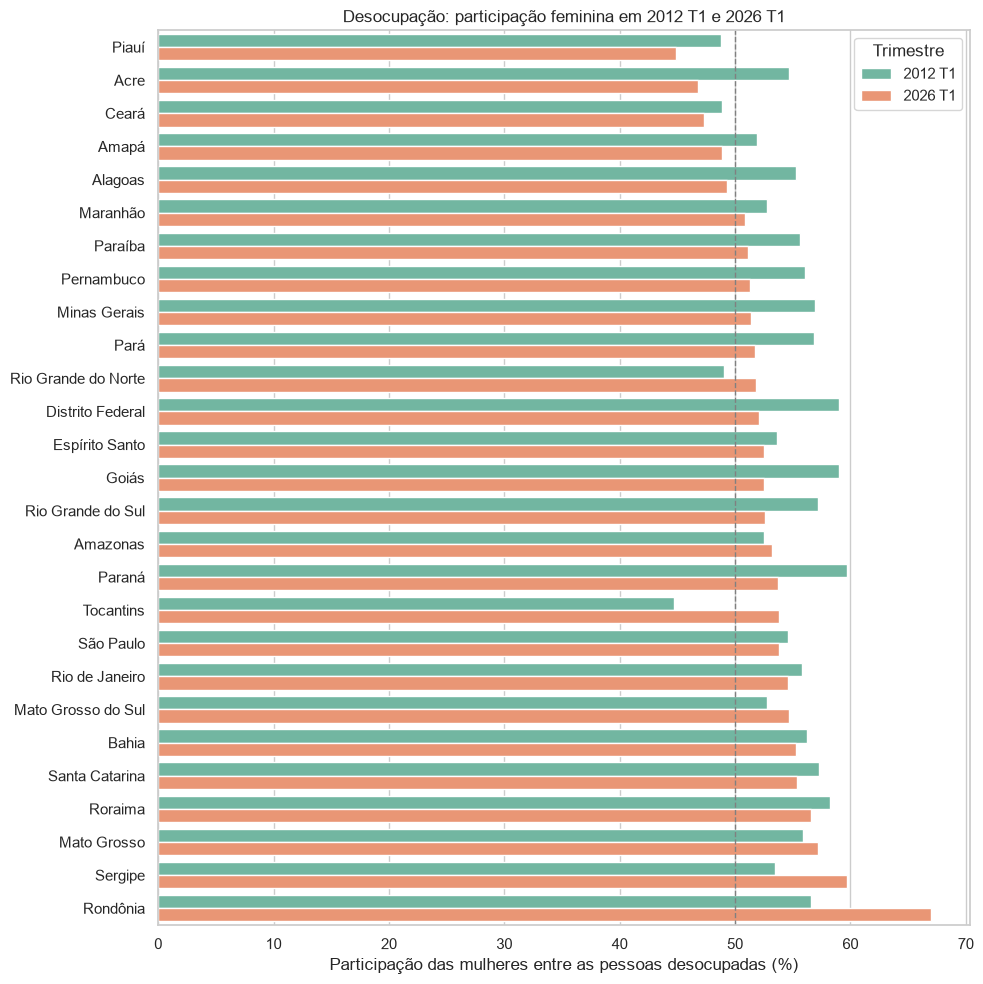

In [9]:
fig, ax = plt.subplots(figsize=(10, 10))
sns.barplot(
    data=longo,
    y="Estado",
    x="Participacao_mulheres",
    hue="Ano",
    hue_order=["2012 T1", "2026 T1"],
    order=ordem,
    ax=ax,
)
ax.axvline(50, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Participação das mulheres entre as pessoas desocupadas (%)")
ax.set_ylabel("")
ax.set_title("Desocupação: participação feminina em 2012 T1 e 2026 T1")
ax.legend(title="Trimestre")
fig.tight_layout()
plt.show()

## 5. Variação entre 2012 e 2026

A variação é medida em pontos percentuais. Barras à direita da linha zero indicam aumento da participação feminina; à esquerda, queda.

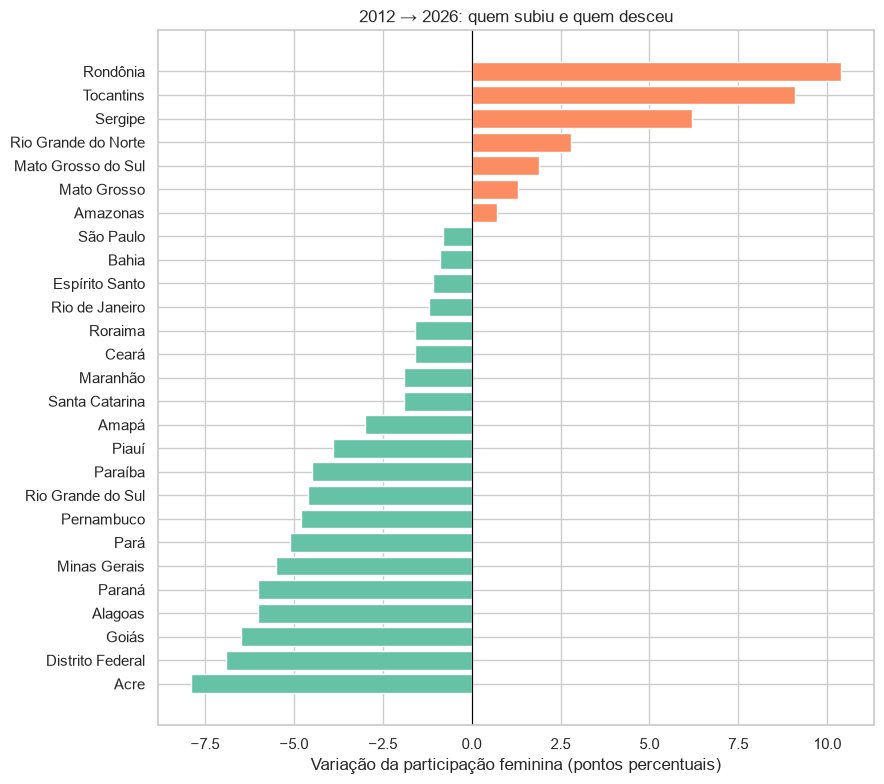

In [10]:
variacao = comp.sort_values("var_mulheres_pp")
cores = ["#fc8d62" if valor > 0 else "#66c2a5" for valor in variacao["var_mulheres_pp"]]

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(variacao["Estado"], variacao["var_mulheres_pp"], color=cores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Variação da participação feminina (pontos percentuais)")
ax.set_ylabel("")
ax.set_title("2012 → 2026: quem subiu e quem desceu")
fig.tight_layout()
plt.show()

## 6. Cruzamento com as horas de cuidados e afazeres domésticos

Cada ponto compara as horas médias de homens e mulheres no mesmo estado. A diagonal representa horas iguais; pontos acima dela indicam mais horas dedicadas às mulheres.

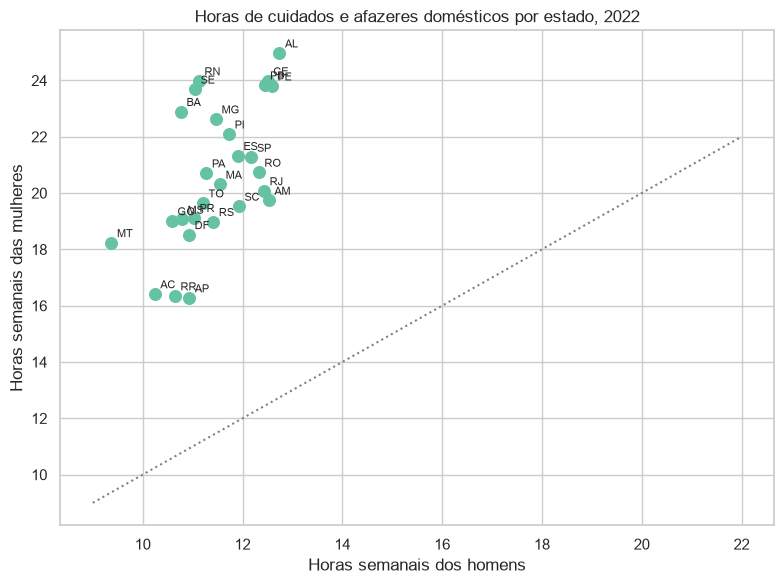

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(comp["horas_homem"], comp["horas_mulher"], s=70, color="#66c2a5")
for _, linha in comp.iterrows():
    ax.annotate(
        linha["Sigla"],
        (linha["horas_homem"], linha["horas_mulher"]),
        textcoords="offset points",
        xytext=(4, 4),
        fontsize=8,
    )
limite = [9, 22]
ax.plot(limite, limite, linestyle=":", color="gray")
ax.set_xlabel("Horas semanais dos homens")
ax.set_ylabel("Horas semanais das mulheres")
ax.set_title("Horas de cuidados e afazeres domésticos por estado, 2022")
fig.tight_layout()
plt.show()

## 7. Resumo dos cruzamentos

A média nacional de horas da Tabela 1.1.1 é usada apenas como referência. As correlações abaixo são calculadas somente com as 27 unidades da federação.

In [12]:
acima_media_mulher = comp.loc[comp["horas_mulher"] > media_nacional_mulher, "Estado"].tolist()
abaixo_50_2026 = comp.loc[comp["mulheres_2026"] < 50, "Estado"].tolist()
print(f"Média nacional total de horas: {media_nacional:.2f}")
print(f"Média nacional de horas das mulheres: {media_nacional_mulher:.2f}")
print("Estados acima da média nacional de horas das mulheres:", acima_media_mulher)
print("Estados com menos de 50% de mulheres em 2026 T1:", abaixo_50_2026)
print("Média da participação feminina nas UFs — 2012:", round(comp["mulheres_2012"].mean(), 1))
print("Média da participação feminina nas UFs — 2026:", round(comp["mulheres_2026"].mean(), 1))
correlacoes = pd.Series({
    "participação feminina 2026 × horas das mulheres": comp["mulheres_2026"].corr(comp["horas_mulher"]),
    "variação feminina × diferença de horas": comp["var_mulheres_pp"].corr(comp["gap_horas"]),
})
correlacoes.round(3)

Média nacional total de horas: 16.99
Média nacional de horas das mulheres: 21.22
Estados acima da média nacional de horas das mulheres: ['Alagoas', 'Bahia', 'Ceará', 'Espírito Santo', 'Minas Gerais', 'Paraíba', 'Pernambuco', 'Piauí', 'Rio Grande do Norte', 'Sergipe', 'São Paulo']
Estados com menos de 50% de mulheres em 2026 T1: ['Acre', 'Alagoas', 'Amapá', 'Ceará', 'Piauí']
Média da participação feminina nas UFs — 2012: 54.6
Média da participação feminina nas UFs — 2026: 53.0


participação feminina 2026 × horas das mulheres   -0.087
variação feminina × diferença de horas             0.108
dtype: float64